In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

columns = [
    'Variance',
    'Skewness',
    'Curtosis',
    'Entropy',
    'Class'
]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head(10)

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.80730,-0.44699,0
1,4.54590,8.1674,-2.45860,-1.46210,0
2,3.86600,-2.6383,1.92420,0.10645,0
3,3.45660,9.5228,-4.01120,-3.59440,0
4,0.32924,-4.4552,4.57180,-0.98880,0
5,4.36840,9.6718,-3.96060,-3.16250,0
6,3.59120,3.0129,0.72888,0.56421,0
7,2.09220,-6.8100,8.46360,-0.60216,0
8,3.20320,5.7588,-0.75345,-0.61251,0
9,1.53560,9.1772,-2.27180,-0.73535,0


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)


Number of rows: 1372
Number of columns: 5
Dataset shape: (1372, 5)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [ ]:
print(df.isnull().sum())

Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64


In [ ]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 24


In [ ]:
df.describe()

,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [ ]:
print(df['Class'].value_counts())

Class
0    762
1    610
Name: count, dtype: int64


In [ ]:
print(df['Class'].value_counts(normalize=True) * 100)

Class
0    55.539359
1    44.460641
Name: proportion, dtype: float64


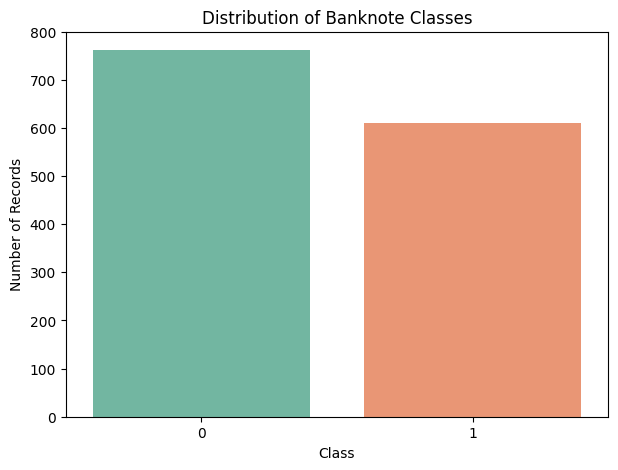

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Banknote Classes")
plt.xlabel("Class")
plt.ylabel("Number of Records")

plt.show()


<Figure size 1200x800 with 0 Axes>

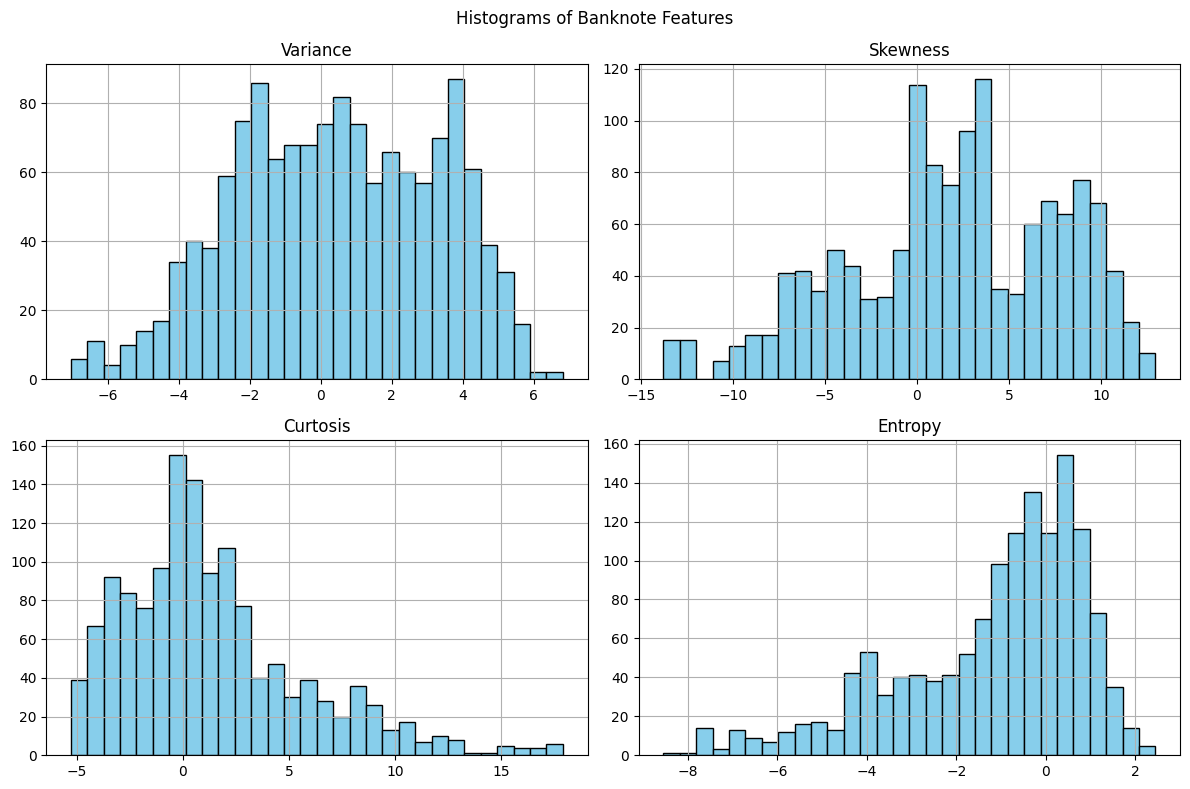

In [ ]:
plt.figure(figsize=(12, 8))

df[['Variance', 'Skewness', 'Curtosis', 'Entropy']].hist(
    bins=30,
    figsize=(12, 8),
    color='skyblue',
    edgecolor='black'
)

plt.suptitle("Histograms of Banknote Features")

plt.tight_layout()

plt.show()

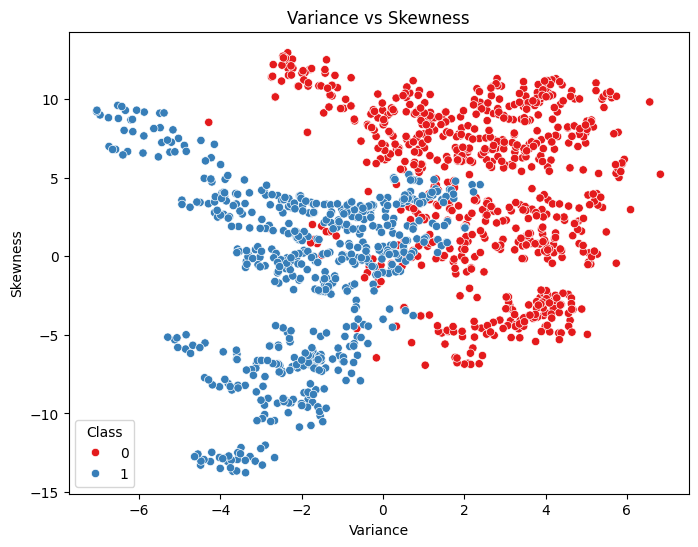

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Variance',
    y='Skewness',
    hue='Class',
    palette='Set1'
)

plt.title("Variance vs Skewness")
plt.xlabel("Variance")
plt.ylabel("Skewness")

plt.show()

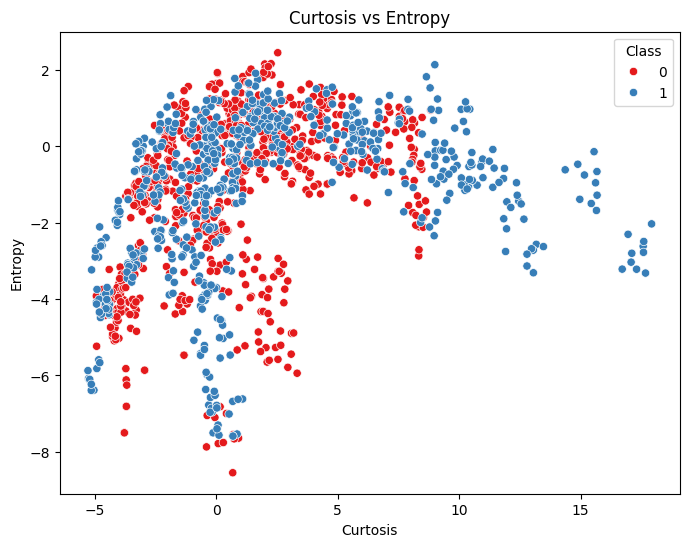

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Curtosis',
    y='Entropy',
    hue='Class',
    palette='Set1'
)

plt.title("Curtosis vs Entropy")
plt.xlabel("Curtosis")
plt.ylabel("Entropy")

plt.show()

In [ ]:

# Step 8: Separating Input Features and Target Variable

# Independent variables (Input Features)
X = df[['Variance', 'Skewness', 'Curtosis', 'Entropy']]

# Dependent variable (Target)
y = df['Class']

# Display the shapes
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

# Display first five records
print("\nInput Features (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())


Shape of X: (1372, 4)
Shape of y: (1372,)

Input Features (X):


,Variance,Skewness,Curtosis,Entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880



Target Variable (y):


,Class
0,0
1,0
2,0
3,0
4,0


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the shapes
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (1097, 4)
Shape of X_test: (275, 4)
Shape of y_train: (1097,)
Shape of y_test: (275,)


In [ ]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])

print("\nTesting data after scaling:")
print(X_test_scaled[:5])

Training data after scaling:
[[ 0.39687699  0.05746643 -1.03953765  0.51951506]
 [-0.38173115 -0.22255311 -0.41215984  0.26034815]
 [ 1.25707446 -0.2779253  -0.11902626  1.13526037]
 [-0.10891208 -0.29720014 -0.70982581  0.85710298]
 [-1.1841959  -0.41950842  0.27444212  1.22779629]]

Testing data after scaling:
[[ 0.67206974  0.95146612 -0.31989126 -0.25003035]
 [-0.6719866   0.04589915 -0.4320298  -0.21511024]
 [-0.4403584   1.30297244 -1.1930052  -2.98014804]
 [-0.30693183 -0.2253577  -0.4446213   0.88712385]
 [-0.90146651 -1.52062841  1.19614286  0.41535648]]


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [ ]:
import pandas as pd

# Predict the class labels
y_pred = model.predict(X_test_scaled)

# Display actual and predicted classes
comparison = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Class": y_pred
})

print("Actual vs Predicted Classes:")
display(comparison.head(15))

Actual vs Predicted Classes:


,Actual Class,Predicted Class
385,0,0
899,1,1
47,0,0
1018,1,1
786,1,1
1346,1,1
645,0,0
32,0,0
200,0,0
887,1,1


In [ ]:
# Predict probabilities for each class
y_prob = model.predict_proba(X_test_scaled)

# Create a probability table
probability_results = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Class": y_pred,
    "Probability Class 0": y_prob[:, 0],
    "Probability Class 1": y_prob[:, 1]
})

print("Predicted Probabilities:")
display(probability_results.head(10))

Predicted Probabilities:


,Actual Class,Predicted Class,Probability Class 0,Probability Class 1
385,0,0,0.999576,0.000424
899,1,1,0.033572,0.966428
47,0,0,0.755631,0.244369
1018,1,1,0.035568,0.964432
786,1,1,0.006959,0.993041
1346,1,1,0.259981,0.740019
645,0,0,0.999274,0.000726
32,0,0,0.999799,0.000201
200,0,0,0.996741,0.003259
887,1,1,0.077905,0.922095


In [ ]:
# Check correct and incorrect predictions
comparison["Correct Prediction"] = (
    comparison["Actual Class"] == comparison["Predicted Class"]
)

print("Correct predictions:")
display(comparison[comparison["Correct Prediction"]].head(5))

print("Incorrect predictions:")
display(comparison[~comparison["Correct Prediction"]].head(5))

Correct predictions:


,Actual Class,Predicted Class,Correct Prediction
385,0,0,True
899,1,1,True
47,0,0,True
1018,1,1,True
786,1,1,True


Incorrect predictions:


,Actual Class,Predicted Class,Correct Prediction
476,0,1,False
315,0,1,False
170,0,1,False
498,0,1,False
345,0,1,False


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9709090909090909
Accuracy Percentage: 97.0909090909091 %
Precision: 0.9384615384615385
Recall: 1.0
F1-score: 0.9682539682539683

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275



Confusion Matrix:
[[145   8]
 [  0 122]]

True Negative (TN): 145
False Positive (FP): 8
False Negative (FN): 0
True Positive (TP): 122


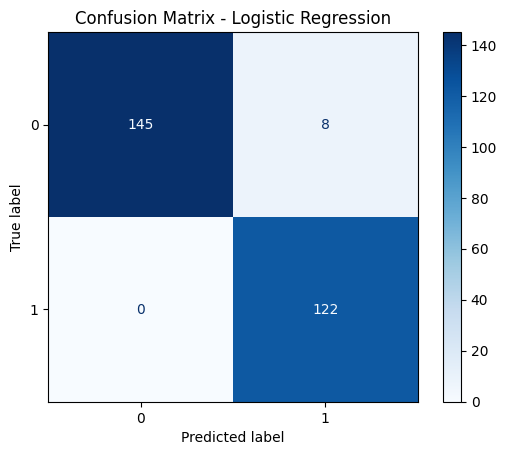

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Extract values
TN, FP, FN, TP = cm.ravel()

print("\nTrue Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)

# Display visual confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Probability of Class 1
prob_class1 = y_prob[:, 1]

thresholds = [0.30, 0.50, 0.70]

results = []

for threshold in thresholds:

    # Predict based on threshold
    y_threshold = (prob_class1 >= threshold).astype(int)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_threshold)
    precision = precision_score(
        y_test, y_threshold, zero_division=0
    )
    recall = recall_score(
        y_test, y_threshold, zero_division=0
    )
    f1 = f1_score(
        y_test, y_threshold, zero_division=0
    )

    # Confusion matrix
    cm_threshold = confusion_matrix(
        y_test, y_threshold, labels=[0, 1]
    )

    TN, FP, FN, TP = cm_threshold.ravel()

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP
    })

# Display results
threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,0.3,0.9709,0.9385,1.0,0.9683,145,8,0,122
1,0.5,0.9709,0.9385,1.0,0.9683,145,8,0,122
2,0.7,0.9964,0.9919,1.0,0.9959,152,1,0,122


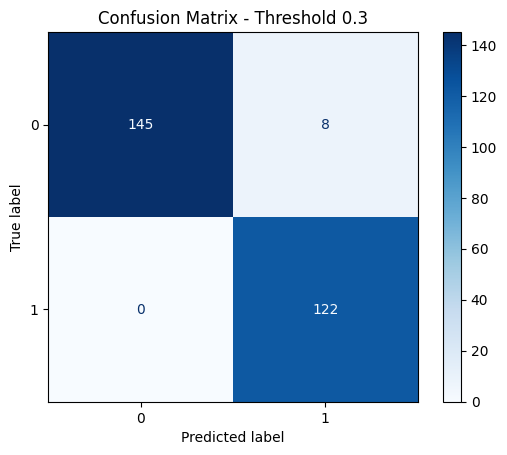

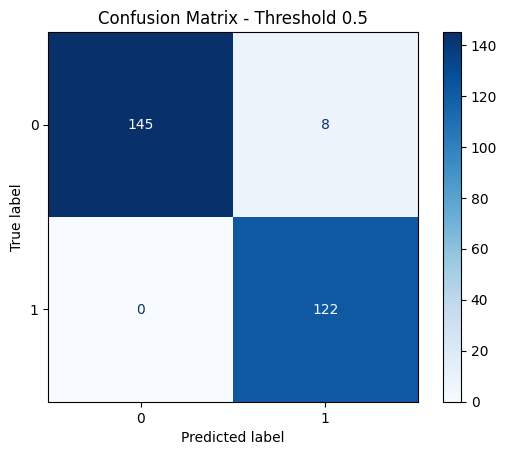

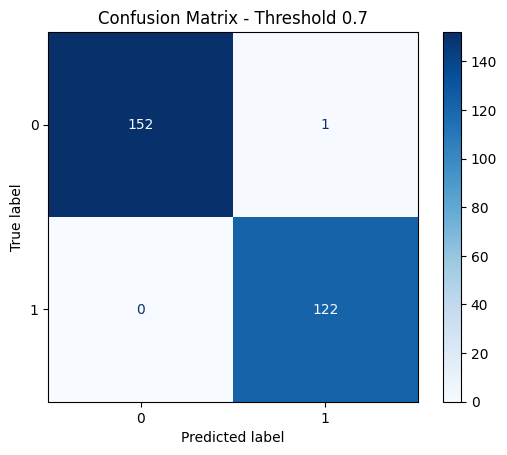

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for threshold in thresholds:

    y_threshold = (prob_class1 >= threshold).astype(int)

    cm_threshold = confusion_matrix(
        y_test,
        y_threshold,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_threshold,
        display_labels=[0, 1]
    )

    disp.plot(cmap="Blues")

    plt.title(f"Confusion Matrix - Threshold {threshold}")
    plt.show()